In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [5]:
df = pd.read_csv(
    "Market_Basket_Retail_Dataset.csv"
)

display(df.head(10))

,TransactionID,Product
0,1,Milk
1,1,Bread
2,1,Butter
3,1,Ketchup
4,1,Noodles
5,2,Coffee
6,2,Sugar
7,2,Biscuits
8,3,Milk
9,3,Bread


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2887
Columns: 2


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2887 entries, 0 to 2886
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   TransactionID  2887 non-null   int64
 1   Product        2887 non-null   str  
dtypes: int64(1), str(1)
memory usage: 64.1 KB


In [6]:
df.describe(include='all')

,TransactionID,Product
count,2887.000000,2887
unique,NaN,40
top,NaN,Biscuits
freq,NaN,146
mean,345.955663,NaN
std,198.997268,NaN
min,1.000000,NaN
25%,177.000000,NaN
50%,343.000000,NaN
75%,515.500000,NaN


In [7]:
print("Columns in Dataset:")
for column in df.columns:
    print("-", column)

Columns in Dataset:
- TransactionID
- Product


In [8]:
total_transactions = df['TransactionID'].nunique()

print("Total Transactions:", total_transactions)

Total Transactions: 700


In [9]:
total_products = df['Product'].nunique()

print("Total Unique Products:", total_products)

Total Unique Products: 40


In [10]:
print("Total Product Records:", len(df))

Total Product Records: 2887


In [11]:
missing_values = df.isnull().sum()

display(missing_values)

TransactionID    0
Product          0
dtype: int64

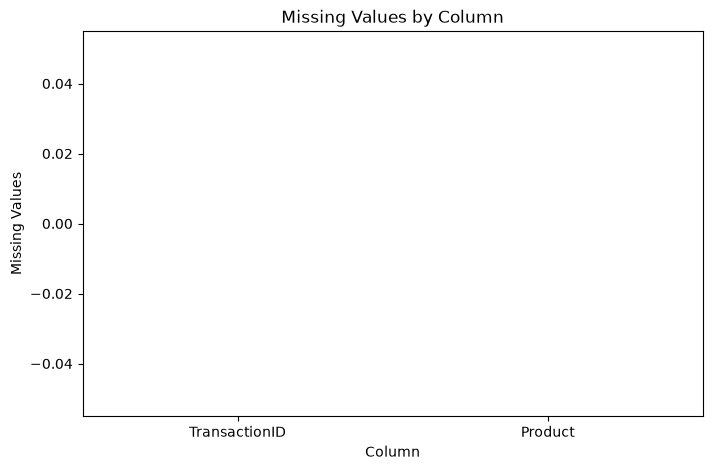

In [12]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=missing_values.index,
    y=missing_values.values
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Values")

plt.show()

In [13]:
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


In [14]:
df = df.drop_duplicates()

print("Dataset after removing duplicates:", df.shape)

Dataset after removing duplicates: (2887, 2)


In [15]:
display(
    df.dtypes.to_frame("Data Type")
)

,Data Type
TransactionID,int64
Product,str


In [16]:
unique_products = sorted(
    df['Product'].unique()
)

print("Unique Products:")
print(unique_products)

Unique Products:
['Apples', 'Bananas', 'Biscuits', 'Bread', 'Butter', 'Cereal', 'Cheese', 'Chicken', 'Chips', 'Chocolate', 'Coffee', 'Cooking Oil', 'Detergent', 'Eggs', 'Fish', 'Flour', 'Ice Cream', 'Juice', 'Ketchup', 'Mayonnaise', 'Milk', 'Noodles', 'Onions', 'Oranges', 'Pasta', 'Potatoes', 'Rice', 'Salt', 'Sausage', 'Shampoo', 'Soap', 'Soft Drink', 'Sugar', 'Tea', 'Tissue', 'Tomato Sauce', 'Toothbrush', 'Toothpaste', 'Water', 'Yogurt']


In [17]:
product_frequency = (
    df['Product']
    .value_counts()
    .reset_index()
)

product_frequency.columns = [
    'Product',
    'Purchase_Count'
]

display(product_frequency)

,Product,Purchase_Count
0,Biscuits,146
1,Butter,105
2,Sugar,105
3,Bread,101
4,Toothpaste,99
5,Ice Cream,92
6,Milk,91
7,Pasta,89
8,Cheese,89
9,Bananas,88


In [18]:
top_10_products = product_frequency.head(10)

display(top_10_products)

,Product,Purchase_Count
0,Biscuits,146
1,Butter,105
2,Sugar,105
3,Bread,101
4,Toothpaste,99
5,Ice Cream,92
6,Milk,91
7,Pasta,89
8,Cheese,89
9,Bananas,88


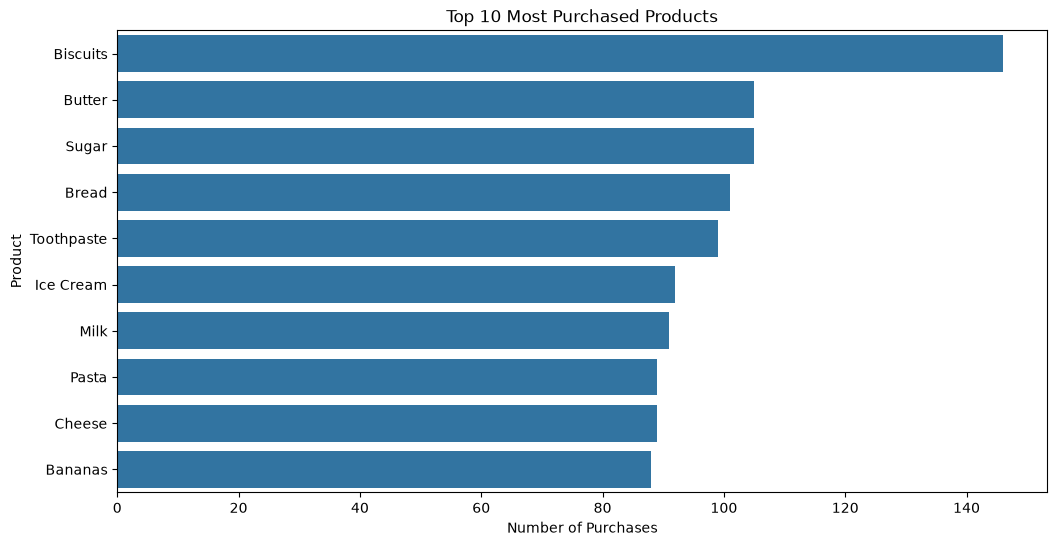

In [19]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_10_products,
    x='Purchase_Count',
    y='Product'
)

plt.title("Top 10 Most Purchased Products")
plt.xlabel("Number of Purchases")
plt.ylabel("Product")

plt.show()

In [20]:
bottom_10_products = product_frequency.tail(10)

display(bottom_10_products)

,Product,Purchase_Count
30,Juice,58
31,Mayonnaise,43
32,Sausage,42
33,Water,41
34,Apples,41
35,Oranges,39
36,Flour,36
37,Detergent,36
38,Tissue,35
39,Yogurt,33


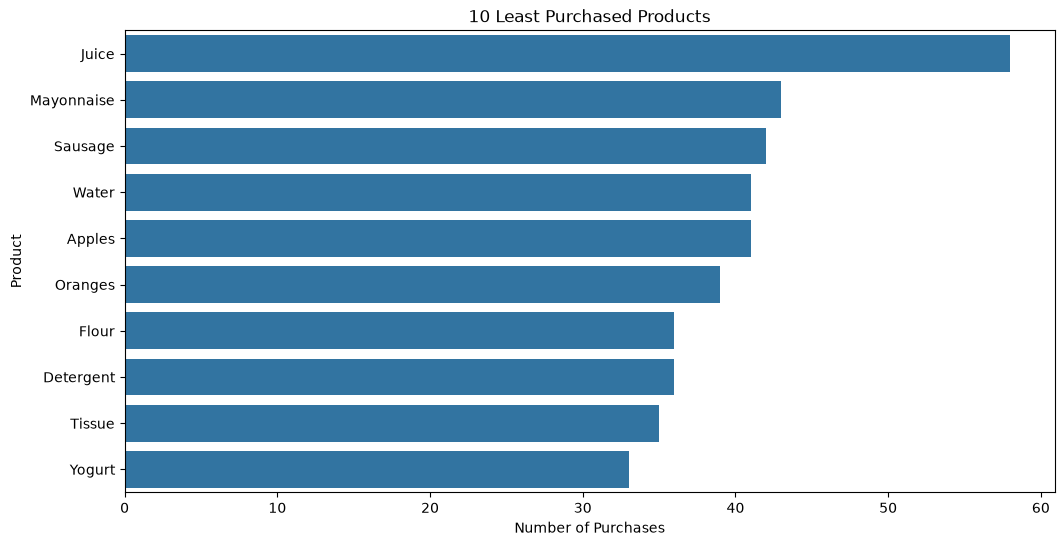

In [21]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=bottom_10_products,
    x='Purchase_Count',
    y='Product'
)

plt.title("10 Least Purchased Products")
plt.xlabel("Number of Purchases")
plt.ylabel("Product")

plt.show()

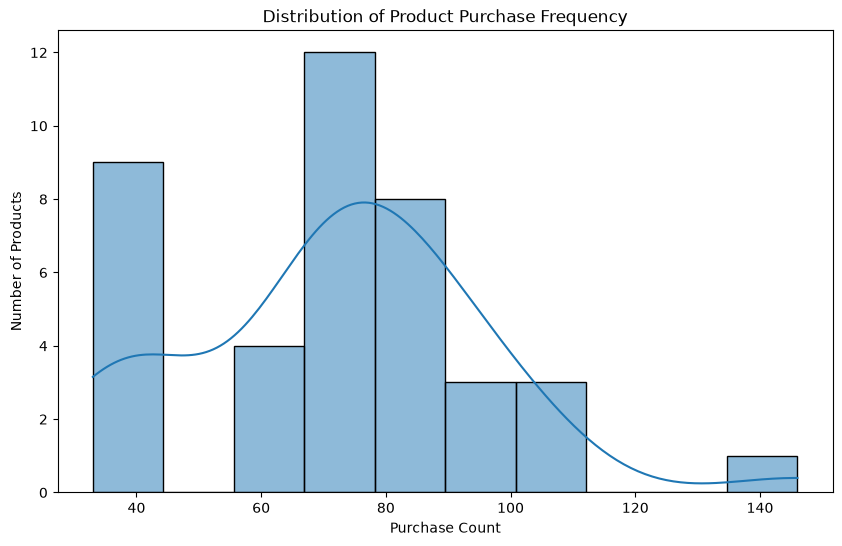

In [22]:
plt.figure(figsize=(10,6))

sns.histplot(
    product_frequency['Purchase_Count'],
    bins=10,
    kde=True
)

plt.title("Distribution of Product Purchase Frequency")
plt.xlabel("Purchase Count")
plt.ylabel("Number of Products")

plt.show()

In [23]:
transaction_size = (
    df.groupby('TransactionID')
    .size()
)

print(
    "Average Products per Transaction:",
    round(transaction_size.mean(), 2)
)

Average Products per Transaction: 4.12


In [24]:
print(
    "Minimum Products in a Transaction:",
    transaction_size.min()
)

print(
    "Maximum Products in a Transaction:",
    transaction_size.max()
)

Minimum Products in a Transaction: 2
Maximum Products in a Transaction: 7


In [25]:
basket_distribution = (
    transaction_size
    .value_counts()
    .sort_index()
)

display(basket_distribution)

2     87
3    164
4    163
5    168
6     97
7     21
Name: count, dtype: int64

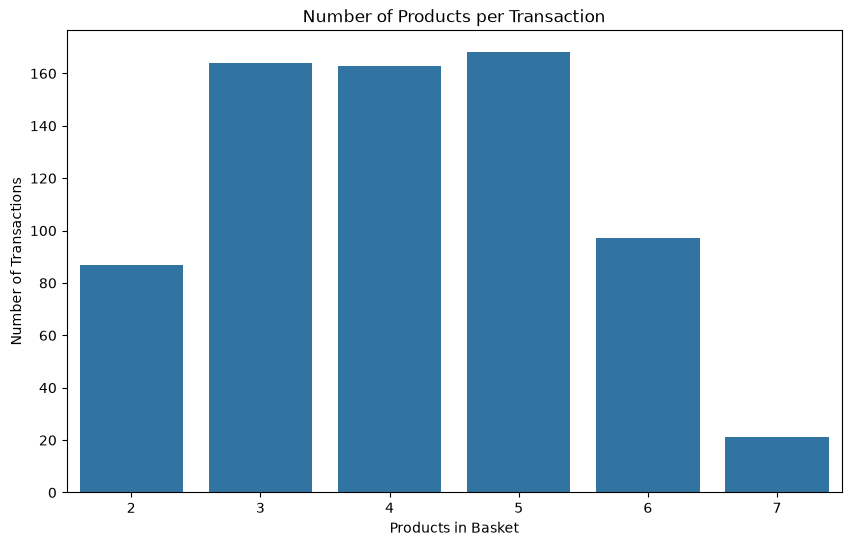

In [26]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=basket_distribution.index,
    y=basket_distribution.values
)

plt.title("Number of Products per Transaction")
plt.xlabel("Products in Basket")
plt.ylabel("Number of Transactions")

plt.show()

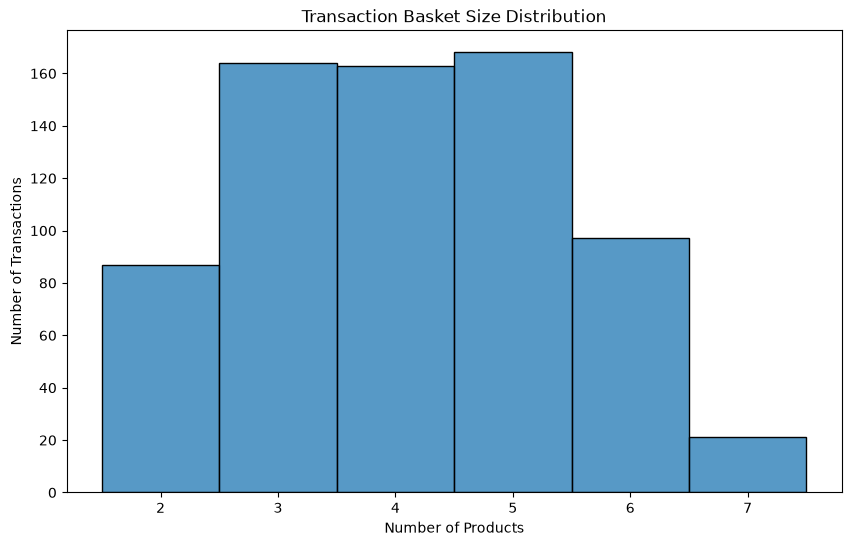

In [27]:
plt.figure(figsize=(10,6))

sns.histplot(
    transaction_size,
    bins=range(
        transaction_size.min(),
        transaction_size.max() + 2
    ),
    discrete=True
)

plt.title("Transaction Basket Size Distribution")
plt.xlabel("Number of Products")
plt.ylabel("Number of Transactions")

plt.show()

In [28]:
average_purchase = df['Product'].value_counts().mean()

print(
    "Average Purchase Count per Product:",
    round(average_purchase, 2)
)

Average Purchase Count per Product: 72.18


In [29]:
most_common_product = (
    df['Product'].value_counts().idxmax()
)

most_common_count = (
    df['Product'].value_counts().max()
)

print("Most Purchased Product:", most_common_product)
print("Purchase Count:", most_common_count)

Most Purchased Product: Biscuits
Purchase Count: 146


In [30]:
least_common_product = (
    df['Product'].value_counts().idxmin()
)

least_common_count = (
    df['Product'].value_counts().min()
)

print("Least Purchased Product:", least_common_product)
print("Purchase Count:", least_common_count)

Least Purchased Product: Yogurt
Purchase Count: 33


In [31]:
product_percentage = (
    df['Product']
    .value_counts(normalize=True)
    * 100
)

product_percentage = (
    product_percentage
    .reset_index()
)

product_percentage.columns = [
    'Product',
    'Percentage'
]

display(product_percentage.head(15))

,Product,Percentage
0,Biscuits,5.057153
1,Butter,3.636993
2,Sugar,3.636993
3,Bread,3.498441
4,Toothpaste,3.429165
5,Ice Cream,3.186699
6,Milk,3.152061
7,Pasta,3.082785
8,Cheese,3.082785
9,Bananas,3.048147


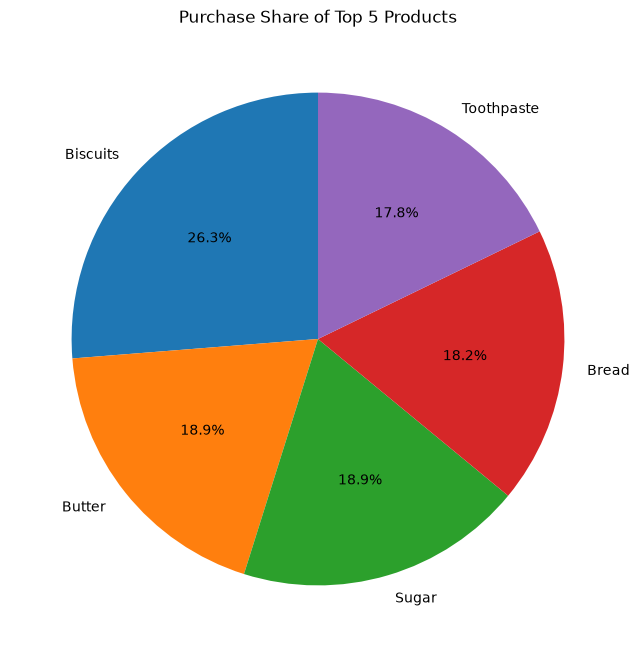

In [32]:
top_5 = df['Product'].value_counts().head(5)

plt.figure(figsize=(8,8))

plt.pie(
    top_5.values,
    labels=top_5.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Purchase Share of Top 5 Products")

plt.show()

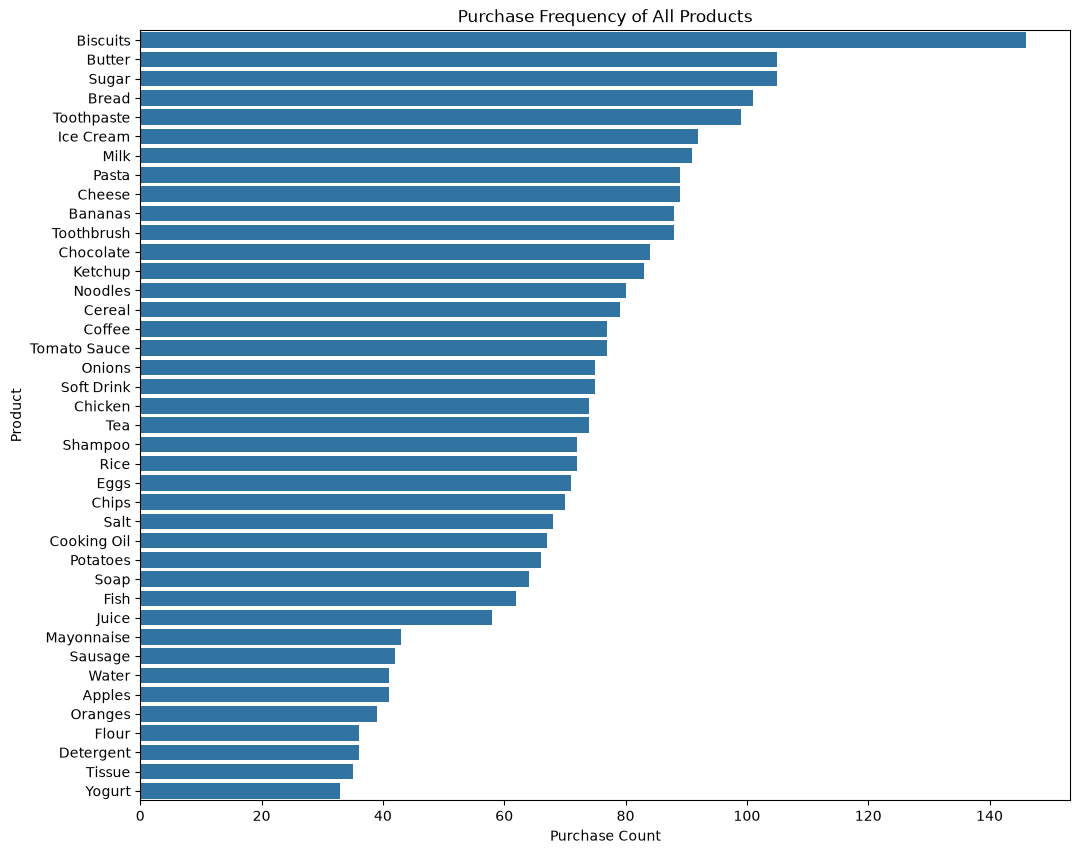

In [33]:
plt.figure(figsize=(12,10))

sns.barplot(
    data=product_frequency,
    x='Purchase_Count',
    y='Product'
)

plt.title("Purchase Frequency of All Products")
plt.xlabel("Purchase Count")
plt.ylabel("Product")

plt.show()

In [35]:
transaction_summary = (
    df.groupby('TransactionID')
    .agg(
        Number_of_Products=('Product', 'count'),
        Products=('Product', lambda x: ', '.join(x))
    )
    .reset_index()
)

# Find the 10 largest baskets
largest_baskets = (
    transaction_summary
    .sort_values(
        by='Number_of_Products',
        ascending=False
    )
    .head(10)
)

display(largest_baskets)

,TransactionID,Number_of_Products,Products
691,692,7,"Toothpaste, Apples, Tissue, Butter, Rice, Cere..."
408,409,7,"Fish, Cereal, Chicken, Soft Drink, Shampoo, No..."
448,449,7,"Bananas, Water, Ice Cream, Potatoes, Toothbrus..."
485,486,7,"Eggs, Milk, Bananas, Coffee, Salt, Cheese, Tea"
382,383,7,"Cereal, Flour, Sugar, Fish, Sausage, Onions, T..."
462,463,7,"Yogurt, Salt, Bananas, Mayonnaise, Noodles, Eg..."
482,483,7,"Fish, Onions, Sugar, Soft Drink, Toothbrush, C..."
500,501,7,"Toothpaste, Chicken, Noodles, Butter, Cheese, ..."
339,340,7,"Potatoes, Ice Cream, Juice, Rice, Fish, Shampo..."
196,197,7,"Soap, Ice Cream, Cereal, Fish, Tissue, Butter,..."


In [37]:
product_frequency['Popularity'] = pd.cut(
    product_frequency['Purchase_Count'],
    bins=3,
    labels=[
        'Low',
        'Medium',
        'High'
    ]
)

display(product_frequency)

,Product,Purchase_Count,Popularity
0,Biscuits,146,High
1,Butter,105,Medium
2,Sugar,105,Medium
3,Bread,101,Medium
4,Toothpaste,99,Medium
5,Ice Cream,92,Medium
6,Milk,91,Medium
7,Pasta,89,Medium
8,Cheese,89,Medium
9,Bananas,88,Medium


Popularity
Medium    23
Low       16
High       1
Name: count, dtype: int64

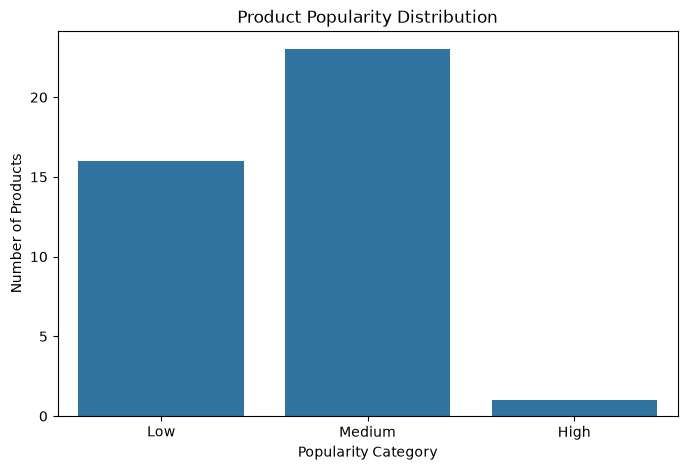

In [38]:
popularity_counts = (
    product_frequency['Popularity']
    .value_counts()
)

display(popularity_counts)

plt.figure(figsize=(8,5))

sns.barplot(
    x=popularity_counts.index,
    y=popularity_counts.values
)

plt.title("Product Popularity Distribution")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Products")

plt.show()

In [39]:
print("=" * 50)
print("       RETAIL DATASET SUMMARY")
print("=" * 50)

print("Total Transactions       :", df['TransactionID'].nunique())
print("Total Products           :", df['Product'].nunique())
print("Total Product Records   :", len(df))
print(
    "Average Basket Size     :",
    round(transaction_size.mean(), 2)
)
print(
    "Minimum Basket Size     :",
    transaction_size.min()
)
print(
    "Maximum Basket Size     :",
    transaction_size.max()
)
print(
    "Most Purchased Product  :",
    most_common_product
)

print("=" * 50)

       RETAIL DATASET SUMMARY
Total Transactions       : 700
Total Products           : 40
Total Product Records   : 2887
Average Basket Size     : 4.12
Minimum Basket Size     : 2
Maximum Basket Size     : 7
Most Purchased Product  : Biscuits


In [41]:
import ipywidgets as widgets
from IPython.display import display, clear_output

product_selector = widgets.Dropdown(
    options=sorted(df['Product'].unique()),
    description='Product:',
    style={'description_width': 'initial'}
)

search_button = widgets.Button(
    description='Analyze Product'
)

product_output = widgets.Output()

def analyze_product(button):

    with product_output:

        clear_output()

        selected = product_selector.value

        count = (
            df['Product']
            .value_counts()
            .get(selected, 0)
        )

        percentage = (
            count / len(df) * 100
        )

        print("Product:", selected)
        print("Purchase Count:", count)
        print(
            "Percentage of All Records:",
            round(percentage, 2), "%"
        )

search_button.on_click(analyze_product)

display(
    product_selector,
    search_button,
    product_output
)

Dropdown(description='Product:', options=('Apples', 'Bananas', 'Biscuits', 'Bread', 'Butter', 'Cereal', 'Chees…

Button(description='Analyze Product', style=ButtonStyle())

Output()

In [43]:
basket_slider = widgets.IntSlider(
    value=3,
    min=int(transaction_size.min()),
    max=int(transaction_size.max()),
    step=1,
    description='Basket Size:',
    style={'description_width': 'initial'}
)

basket_output = widgets.Output()

def show_baskets(change):

    with basket_output:

        clear_output()

        selected_size = basket_slider.value

        transactions = transaction_summary[
            transaction_summary[
                'Number_of_Products'
            ] == selected_size
        ]

        print(
            "Transactions containing",
            selected_size,
            "products:"
        )

        display(
            transactions.head(20)
        )

basket_slider.observe(
    show_baskets,
    names='value'
)

display(
    basket_slider,
    basket_output
)

IntSlider(value=3, description='Basket Size:', max=7, min=2, style=SliderStyle(description_width='initial'))

Output()

In [44]:
basket_df = (
    transaction_size
    .value_counts()
    .sort_index()
    .reset_index()
)

basket_df.columns = [
    'Basket_Size',
    'Transaction_Count'
]

display(basket_df)

,Basket_Size,Transaction_Count
0,2,87
1,3,164
2,4,163
3,5,168
4,6,97
5,7,21


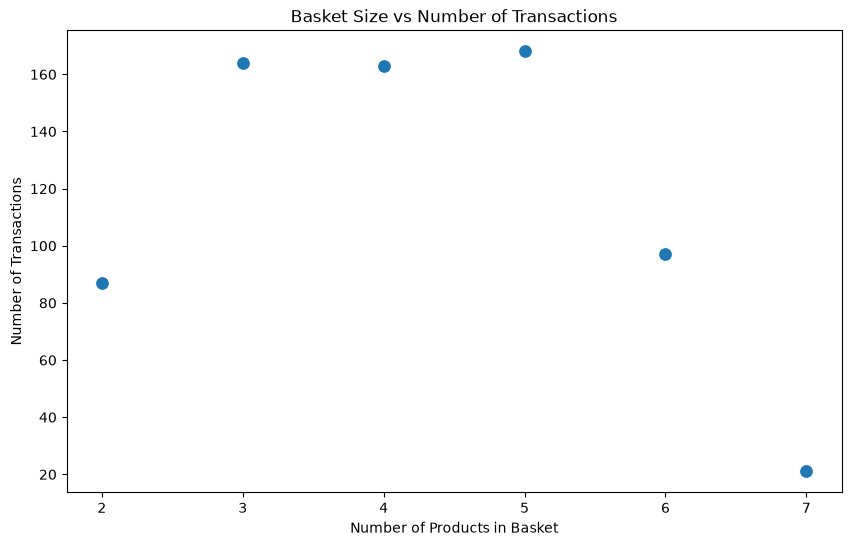

In [45]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=basket_df,
    x='Basket_Size',
    y='Transaction_Count',
    s=100
)

plt.title(
    "Basket Size vs Number of Transactions"
)

plt.xlabel("Number of Products in Basket")
plt.ylabel("Number of Transactions")

plt.show()

In [46]:
print("========== DATA ANALYSIS FINDINGS ==========")

print(
    f"1. The dataset contains "
    f"{df['TransactionID'].nunique()} transactions."
)

print(
    f"2. There are "
    f"{df['Product'].nunique()} unique products."
)

print(
    f"3. The dataset contains "
    f"{len(df)} product records."
)

print(
    f"4. The average basket contains "
    f"{transaction_size.mean():.2f} products."
)

print(
    f"5. The most frequently purchased product is "
    f"{most_common_product}."
)

print(
    f"6. The largest basket contains "
    f"{transaction_size.max()} products."
)

print("============================================")

========== DATA ANALYSIS FINDINGS ==========
1. The dataset contains 700 transactions.
2. There are 40 unique products.
3. The dataset contains 2887 product records.
4. The average basket contains 4.12 products.
5. The most frequently purchased product is Biscuits.
6. The largest basket contains 7 products.


In [8]:
import gradio as gr
import pandas as pd
import pickle
import matplotlib.pyplot as plt


# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv("Market_Basket_Retail_Dataset.csv")

with open("market_basket_model.pkl", "rb") as file:
    model = pickle.load(file)

frequent_itemsets = model["frequent_itemsets"]
rules = model["rules"]


# ============================================================
# DATA ANALYSIS
# ============================================================

total_transactions = df["TransactionID"].nunique()
total_products = df["Product"].nunique()
total_records = len(df)

transaction_size = df.groupby("TransactionID").size()

average_basket = transaction_size.mean()
minimum_basket = transaction_size.min()
maximum_basket = transaction_size.max()

product_frequency = (
    df["Product"]
    .value_counts()
    .reset_index()
)

product_frequency.columns = [
    "Product",
    "Purchase_Count"
]

most_common_product = product_frequency.iloc[0]["Product"]
most_common_count = product_frequency.iloc[0]["Purchase_Count"]

least_common_product = product_frequency.iloc[-1]["Product"]
least_common_count = product_frequency.iloc[-1]["Purchase_Count"]

top_10_products = product_frequency.head(10)

basket_distribution = (
    transaction_size
    .value_counts()
    .sort_index()
    .reset_index()
)

basket_distribution.columns = [
    "Basket_Size",
    "Transaction_Count"
]

products = sorted(
    df["Product"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


# ============================================================
# CHART 1 - TOP PRODUCTS
# ============================================================

def top_products_chart():

    fig, ax = plt.subplots(figsize=(8, 5))

    data = top_10_products.sort_values(
        "Purchase_Count"
    )

    ax.barh(
        data["Product"],
        data["Purchase_Count"]
    )

    ax.set_title("Top 10 Most Purchased Products")
    ax.set_xlabel("Number of Purchases")
    ax.set_ylabel("Product")

    plt.tight_layout()

    return fig


# ============================================================
# CHART 2 - BASKET SIZE
# ============================================================

def basket_chart():

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(
        basket_distribution["Basket_Size"],
        basket_distribution["Transaction_Count"]
    )

    ax.set_title("Basket Size Distribution")
    ax.set_xlabel("Products in Basket")
    ax.set_ylabel("Number of Transactions")

    plt.tight_layout()

    return fig


# ============================================================
# CHART 3 - TOP 5 PRODUCTS
# ============================================================

def top5_chart():

    top5 = product_frequency.head(5)

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.pie(
        top5["Purchase_Count"],
        labels=top5["Product"],
        autopct="%1.1f%%",
        startangle=90
    )

    ax.set_title("Top 5 Product Purchase Share")

    plt.tight_layout()

    return fig


# ============================================================
# RECOMMENDATION FUNCTION
# ============================================================

def recommend(selected):

    if not selected:

        return (
            "Please select at least one product.",
            pd.DataFrame()
        )

    selected = set(selected)

    result = rules[
        rules["antecedents"].apply(
            lambda x: selected.issubset(set(x))
        )
    ].copy()

    if result.empty:

        return (
            "**Selected:** " + " + ".join(selected)
            + "\n\nNo recommendations found.",
            pd.DataFrame()
        )

    result = result.sort_values(
        "confidence",
        ascending=False
    )

    result["antecedents"] = result[
        "antecedents"
    ].apply(
        lambda x: ", ".join(sorted(x))
    )

    result["consequents"] = result[
        "consequents"
    ].apply(
        lambda x: ", ".join(sorted(x))
    )

    result = result[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(20)

    selected_text = (
        "**Selected Products:** "
        + " + ".join(selected)
    )

    return selected_text, result


# ============================================================
# CLEAR SELECTION
# ============================================================

def clear_selection():

    return (
        [],
        "Select one or more products.",
        pd.DataFrame()
    )


# ============================================================
# DASHBOARD
# ============================================================

with gr.Blocks(
    title="Retail Store & Market Basket Dashboard"
) as dashboard:

    # --------------------------------------------------------
    # HEADER
    # --------------------------------------------------------

    gr.Markdown(
        """
        # 🛒 Retail Store & Market Basket Analysis Dashboard

        ### Data Analysis • Basket Analysis • Product Recommendation
        """
    )

    gr.Markdown("---")


    # --------------------------------------------------------
    # KEY STATISTICS
    # --------------------------------------------------------

    gr.Markdown("## 📌 Key Statistics")

    with gr.Row():

        with gr.Column():
            gr.Markdown("### 🧾 Transactions")
            gr.Markdown(f"# {total_transactions}")

        with gr.Column():
            gr.Markdown("### 🛍️ Products")
            gr.Markdown(f"# {total_products}")

        with gr.Column():
            gr.Markdown("### 📦 Records")
            gr.Markdown(f"# {total_records}")

        with gr.Column():
            gr.Markdown("### 🛒 Avg Basket")
            gr.Markdown(f"# {average_basket:.2f}")

        with gr.Column():
            gr.Markdown("### 🔗 Rules")
            gr.Markdown(f"# {len(rules)}")


    gr.Markdown("---")


    # ========================================================
    # TABS
    # ========================================================

    with gr.Tabs():

        # ====================================================
        # TAB 1 - DATA ANALYSIS
        # ====================================================

        with gr.Tab("📊 Data Analysis"):

            gr.Markdown("## 📊 Data Analysis Findings")

            gr.Markdown(
                f"""
**1. Total Transactions:** {total_transactions}

**2. Unique Products:** {total_products}

**3. Total Product Records:** {total_records}

**4. Average Basket Size:** {average_basket:.2f} products

**5. Minimum Basket Size:** {minimum_basket} products

**6. Maximum Basket Size:** {maximum_basket} products

**7. Most Frequently Purchased Product:** {most_common_product}

**8. Purchase Count:** {most_common_count}

**9. Least Frequently Purchased Product:** {least_common_product}

**10. Purchase Count:** {least_common_count}
"""
            )

            gr.Markdown("---")

            with gr.Row():

                with gr.Column():

                    gr.Markdown(
                        "### 🏆 Top 10 Products"
                    )

                    gr.Plot(
                        value=top_products_chart()
                    )

                with gr.Column():

                    gr.Markdown(
                        "### 🛒 Basket Size"
                    )

                    gr.Plot(
                        value=basket_chart()
                    )

            with gr.Row():

                gr.Markdown(
                    "### 🥧 Top 5 Product Share"
                )

                gr.Plot(
                    value=top5_chart()
                )

            gr.Markdown("---")

            gr.Markdown(
                "## 🏆 Product Purchase Frequency"
            )

            gr.Dataframe(
                value=product_frequency,
                interactive=False
            )

            gr.Markdown("---")

            gr.Markdown(
                "## 🛒 Basket Size Distribution"
            )

            gr.Dataframe(
                value=basket_distribution,
                interactive=False
            )


        # ====================================================
        # TAB 2 - MARKET BASKET
        # ====================================================

        with gr.Tab("🔎 Market Basket"):

            gr.Markdown(
                """
                ## 🔎 Market Basket Product Recommendation

                Select one or more products to get recommendations
                from the existing association-rule model.
                """
            )

            with gr.Row():

                # LEFT SIDE

                with gr.Column(scale=1):

                    gr.Markdown(
                        "### 🛍️ Select Products"
                    )

                    product_selector = gr.CheckboxGroup(
                        choices=products,
                        label="Products",
                        info="Select one or more products"
                    )

                    clear_button = gr.Button(
                        "🗑️ Clear Selection"
                    )


                # RIGHT SIDE

                with gr.Column(scale=5):

                    gr.Markdown(
                        "### 📋 Actual Dataset"
                    )

                    gr.Dataframe(
                        value=df,
                        interactive=False
                    )


            gr.Markdown("---")

            gr.Markdown(
                "## 🎯 Product Recommendations"
            )

            selected_text = gr.Markdown(
                "Select one or more products."
            )

            recommendation_output = gr.Dataframe(
                headers=[
                    "antecedents",
                    "consequents",
                    "support",
                    "confidence",
                    "lift"
                ],
                interactive=False
            )


        # ====================================================
        # TAB 3 - FREQUENT ITEMSETS
        # ====================================================

        with gr.Tab("📦 Frequent Itemsets"):

            gr.Markdown(
                "## 📦 Frequent Itemsets"
            )

            frequent_display = frequent_itemsets.copy()

            if "itemsets" in frequent_display.columns:

                frequent_display["itemsets"] = (
                    frequent_display["itemsets"]
                    .apply(
                        lambda x:
                        ", ".join(sorted(x))
                    )
                )

            gr.Dataframe(
                value=frequent_display,
                interactive=False
            )


        # ====================================================
        # TAB 4 - ASSOCIATION RULES
        # ====================================================

        with gr.Tab("🔗 Association Rules"):

            gr.Markdown(
                "## 🔗 Association Rules"
            )

            rules_display = rules.copy()

            if "antecedents" in rules_display.columns:

                rules_display["antecedents"] = (
                    rules_display["antecedents"]
                    .apply(
                        lambda x:
                        ", ".join(sorted(x))
                    )
                )

            if "consequents" in rules_display.columns:

                rules_display["consequents"] = (
                    rules_display["consequents"]
                    .apply(
                        lambda x:
                        ", ".join(sorted(x))
                    )
                )

            gr.Dataframe(
                value=rules_display,
                interactive=False
            )


        # ====================================================
        # TAB 5 - COMPLETE DATASET
        # ====================================================

        with gr.Tab("📋 Complete Dataset"):

            gr.Markdown(
                "## 📋 Complete Retail Dataset"
            )

            gr.Dataframe(
                value=df,
                interactive=False
            )


    # ========================================================
    # BUTTON ACTIONS
    # ========================================================

    product_selector.change(
        fn=recommend,
        inputs=product_selector,
        outputs=[
            selected_text,
            recommendation_output
        ]
    )

    clear_button.click(
        fn=clear_selection,
        inputs=None,
        outputs=[
            product_selector,
            selected_text,
            recommendation_output
        ]
    )


# ============================================================
# LAUNCH
# ============================================================

dashboard.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
